# get TIC catalog data containing Gaia ID for exominer TCEs

In [157]:
from astroquery.mast import Catalogs
import numpy as np

tic_data = Catalogs.query_criteria(catalog="TIC", ID=df_exominer.loc[idx,'TIC ID'].unique())

In [158]:
# Extract unique Gaia IDs and remove masked/null values
gaia_ids = [int(gid) for gid in tic_data['GAIA'] if gid is not np.ma.masked]
len(gaia_ids)

1456

In [159]:
tic_data.to_pandas().to_csv('../data/exominer_tic_data.csv', index=False)

# cross-match TOI TICID with TIC catalog then Gaia catalog using `astroquery.mast`

In [41]:
from astroquery.mast import Catalogs
import numpy as np

# Query the TIC catalog for these IDs
# We specifically want the 'GAIA' column which contains the Gaia DR2/DR3 source_id
tic_data = Catalogs.query_criteria(catalog="TIC", ID=tois['TIC ID'].unique())

In [42]:
tic_data.columns #why no RV?

<TableColumns names=('ID','version','HIP','TYC','UCAC','TWOMASS','SDSS','ALLWISE','GAIA','APASS','KIC','objType','typeSrc','ra','dec','POSflag','pmRA','e_pmRA','pmDEC','e_pmDEC','PMflag','plx','e_plx','PARflag','gallong','gallat','eclong','eclat','Bmag','e_Bmag','Vmag','e_Vmag','umag','e_umag','gmag','e_gmag','rmag','e_rmag','imag','e_imag','zmag','e_zmag','Jmag','e_Jmag','Hmag','e_Hmag','Kmag','e_Kmag','TWOMflag','prox','w1mag','e_w1mag','w2mag','e_w2mag','w3mag','e_w3mag','w4mag','e_w4mag','GAIAmag','e_GAIAmag','Tmag','e_Tmag','TESSflag','SPFlag','Teff','e_Teff','logg','e_logg','MH','e_MH','rad','e_rad','mass','e_mass','rho','e_rho','lumclass','lum','e_lum','d','e_d','ebv','e_ebv','numcont','contratio','disposition','duplicate_id','priority','eneg_EBV','epos_EBV','EBVflag','eneg_Mass','epos_Mass','eneg_Rad','epos_Rad','eneg_rho','epos_rho','eneg_logg','epos_logg','eneg_lum','epos_lum','eneg_dist','epos_dist','distflag','eneg_Teff','epos_Teff','TeffFlag','gaiabp','e_gaiabp','gaiarp','

In [43]:
tic_df = tic_data.to_pandas()[['ID','GAIA','ra','dec','plx','pmRA','pmDEC','Teff']].astype(float)
tic_df.shape

(6490, 8)

https://gaia.aip.de/metadata/gaiadr3/gaia_source/

In [44]:
from astroquery.gaia import Gaia

# Extract unique Gaia IDs and remove masked/null values
gaia_ids = [int(gid) for gid in tic_data['GAIA'] if gid is not np.ma.masked]

# Format the IDs for the SQL 'IN' clause
ids_str = ",".join(map(str, gaia_ids))

# ADQL query to get source_id and radial_velocity
query = f"""
SELECT source_id, radial_velocity, radial_velocity_error, teff_gspphot
FROM gaiadr3.gaia_source
WHERE source_id IN ({ids_str})
"""

# Launch the job
job = Gaia.launch_job_async(query)
results = job.get_results()

INFO: Query finished. [astroquery.utils.tap.core]


In [45]:
import pandas as pd

rv_df = results.to_pandas().astype(float).rename({
    'SOURCE_ID': 'GAIA',
    }, axis=1
                                  )
tic_df = pd.merge(tic_df, rv_df, on='GAIA')
tic_df['TIC ID'] = tic_df['ID'].astype(int).copy()
tic_df.head()

,ID,GAIA,ra,dec,plx,pmRA,pmDEC,Teff,radial_velocity,radial_velocity_error,teff_gspphot,TIC ID
0,257467784.0,2.744957e+18,0.084560,5.044452,2.87259,27.80570,-14.9716,5103.41,20.023235,1.443543,4990.822266,257467784
1,346929661.0,4.231745e+17,0.977583,59.334777,4.88382,-3.07059,-22.4245,6178.00,2.690783,0.363293,5915.730957,346929661
2,352147273.0,2.877081e+18,0.484828,35.998031,11.91350,39.60730,-59.8346,3376.00,-5.530849,5.096278,NaN,352147273
3,396234347.0,2.877051e+18,0.222348,35.752622,23.74870,158.79100,-41.0840,4540.43,-3.999605,0.178812,NaN,396234347
4,405230669.0,2.766146e+18,0.318028,12.039964,2.12960,38.66670,25.3219,5465.01,-3.206803,2.160146,5245.859863,405230669


In [46]:
matches = pd.merge(tois, tic_df, on='TIC ID')

In [47]:
matches = matches.rename({
    'GAIA': 'GaiaDR3',
    'plx': 'parallax',
    'pmRA': 'pmra',
    'pmDEC': 'pmdec',
    'Teff': 'Teff_TIC',
    'teff_gspphot': 'Teff_gaia'
}, axis=1)

(-1000.0, 1000.0)

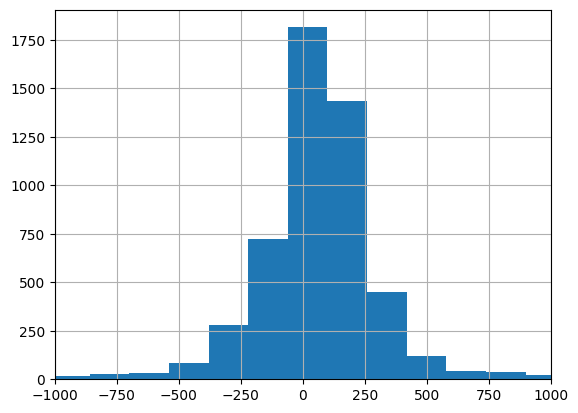

In [48]:
diff = matches['Teff_TIC']-matches['Teff_gaia']
ax = diff.hist(bins=100)
ax.set_xlim(-1000,1000)

In [49]:
diff.std()

np.float64(447.18007602654393)

In [50]:
matches.to_csv('../data/TOIs_GaiaDR3_xmatch_new.csv', index=False)

In [51]:
matches.GaiaDR3.unique().shape, tois.shape

((6074,), (6791, 67))

# cross-match TOI position with Gaia DR3 using `astroquery.xmatch`

In [56]:
import astropy.units as u
from astroquery.xmatch import XMatch
import pandas as pd

gaia_table = XMatch.query(
    cat1=open('../data/TOIs.csv'),
    cat2="vizier:I/355/gaiadr3",  # The Vizier identifier for Gaia DR3
    max_distance=5 * u.arcsec,    # Set the maximum matching radius
    colRA1="ra_deg",  # Column name for Right Ascension in TIC results
    colDec1="dec_deg" # Column name for Declination in TIC results
)
gaia_df = gaia_table.to_pandas()

# results to 6237 matches
matches = gaia_df.copy()

In [57]:
matches.TOI.duplicated().sum()

np.int64(3091)

In [58]:
# Apply magnitude filtering criteria
# For main-sequence stars, the difference between TESS T and Gaia G is around 0–0.5 magnitudes
# Redder stars might have T - G values closer to 1–2 magnitudes.
# For giants or highly reddened stars, the difference could be larger.
if False:
    # results to 5971 matches
    matches = []
    for i, row in gaia_df.iterrows():
        teff=row['Stellar Eff Temp (K)']
        if teff<3500:
            magnitude_threshold = 2
        elif (teff>3500) and (teff<6000):
            magnitude_threshold = 1
        else:
            magnitude_threshold = 1.5
        if abs(row['Gmag'] - row['TESS Mag']) < magnitude_threshold:
            matches.append(row)
    matches = pd.concat(matches, axis=1).T
if False:
    # results to 5700 matches
    magnitude_threshold = 2
    matches = gaia_df[abs(gaia_df['Gmag'] - gaia_df['TESS Mag']) < magnitude_threshold]
if False:
    # results to 4878 matches
    teff_threshold = 1000
    matches = gaia_df[abs(gaia_df['Teff'] - gaia_df['Stellar Eff Temp (K)']) < teff_threshold]
matches.tail()

,angDist,TIC ID,TOI,Previous CTOI,Master,SG1A,SG1B,SG2,SG3,SG4,...,B_AG,E(BP-RP),b_E(BP-RP),B_E(BP-RP),Lib,RAJ2000,DEJ2000,e_RAJ2000,e_DEJ2000,RADEcorJ2000
11149,0.022153,296327387,7091.01,NaN,3,4,3,3,1,4,...,0.6363,0.3340,0.3296,0.3419,PHOENIX,306.609138,49.041269,1.011101,1.053013,-0.0200
11150,0.016252,195483731,7092.01,NaN,3,4,3,3,1,4,...,1.3036,0.6926,0.6812,0.6998,A,310.142459,47.299604,0.594215,0.602640,-0.0171
11151,3.713503,195483731,7092.01,NaN,3,4,3,3,1,4,...,1.0825,0.5772,0.5677,0.5825,PHOENIX,310.141916,47.300566,0.230872,0.229203,0.0439
11152,4.298772,195483731,7092.01,NaN,3,4,3,3,1,4,...,NaN,NaN,NaN,NaN,NaN,310.140702,47.299569,31.385668,25.509037,0.5113
11153,0.033358,62867537,7093.01,NaN,3,4,4,3,3,4,...,0.3186,0.1685,0.1644,0.1715,MARCS,319.409948,48.163338,0.159520,0.174056,0.1083


In [59]:
matches.shape

(11154, 205)

In [60]:
matches['GaiaDR3'] = matches['DR3Name'].apply(lambda x: int(x.split()[-1]))
matches.to_csv('../data/TOIs_GaiaDR3_xmatch.csv', index=False)

In [61]:
idx = tois.TOI.isin(matches.TOI.unique())
tois[~idx].shape

(1, 67)

In [62]:
tois[~idx].to_csv('../data/TOIs_GaiaDR3_xmatch_missing.csv', index=False)